# 00 – Khảo sát bộ dữ liệu (Dataset exploration)

Notebook này kiểm tra nhanh dữ liệu trước khi phân tích:

1. Trạng thái dữ liệu thô (`data/raw/`) và 42 file epoch (`derivatives/v1/epochs/`).
2. Thông tin kỹ thuật: tần số lấy mẫu, số kênh, số mẫu thời gian, montage Colin27 (128 kênh).
3. Bảng kiểm kê 42 đối tượng: số epoch theo điều kiện, số trial trả lời đúng, cờ chất lượng.
4. Phân bố kích thích Standard / Target / Distractor và tập dữ liệu phân loại (39 người).
5. Hành vi: thời gian phản ứng (RT) so với Bảng 5 của paper dataset (Dzianok et al., 2022).

Dữ liệu epoch tải từ GitHub Release `data-v1` (xem mục 5 của `01_preprocessing.ipynb`).

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import mne
import numpy as np
import pandas as pd

from config import (EPOCH_DIR, EVENT_ID, HIGH_IMPEDANCE, N_CHANNELS,
                    PAPER_LISTED_IRREGULAR, QC_SUMMARY, RAW_DIR, SFREQ,
                    SUBJECTS, TASK_MISUNDERSTOOD, TMAX, TMIN)
from src.utils.io import epoch_path

mne.set_log_level("error")
pd.set_option("display.width", 160)
print("MNE", mne.__version__)
print("Epoch dir:", EPOCH_DIR)

MNE 1.13.2
Epoch dir: D:\Coding\EEG\derivatives\v1\epochs


## 1. Dữ liệu thô và file epoch

Dữ liệu thô BrainVision (`.vhdr/.vmrk/.eeg`, 1000 Hz) chỉ cần cho bước tiền xử lý và không được commit. Các bước phân tích V3–V6 chỉ đọc file epoch.

In [2]:
raw_files = sorted(RAW_DIR.rglob("*.vhdr")) if RAW_DIR.exists() else []
print(f"data/raw: {len(raw_files)} file .vhdr" + ("" if raw_files else " (không có trên máy này — không cần cho V3–V6)"))

inventory = pd.DataFrame({
    "subject": SUBJECTS,
    "exists": [epoch_path(s).exists() for s in SUBJECTS],
    "size_mb": [epoch_path(s).stat().st_size / 2**20 if epoch_path(s).exists() else np.nan for s in SUBJECTS],
})
print(f"File epoch: {inventory.exists.sum()}/{len(SUBJECTS)}, tổng {inventory.size_mb.sum() / 1024:.2f} GB")
missing = inventory.loc[~inventory.exists, "subject"].tolist()
assert not missing, f"Thiếu epoch: {missing} — tải từ Release data-v1"
inventory.describe()

data/raw: 0 file .vhdr (không có trên máy này — không cần cho V3–V6)
File epoch: 42/42, tổng 3.89 GB


,size_mb
count,42.000000
mean,94.722140
std,7.914174
min,49.036105
25%,95.174785
50%,96.388734
75%,96.939873
max,108.602711


## 2. Thông tin kỹ thuật của một đối tượng (sub-01)

Kỳ vọng theo `config.py`: 250 Hz (1000 Hz hạ 4 lần), 128 kênh EEG (127 điện cực + FCz tham chiếu được thêm lại), −200..+1000 ms = 301 mẫu, average reference, lọc 0,5–40 Hz.

In [3]:
ep = mne.read_epochs(epoch_path("sub-01"), preload=False)
info = ep.info
print(f"Tần số lấy mẫu  : {info['sfreq']:.0f} Hz")
print(f"Số kênh         : {len(ep.ch_names)} ({', '.join(sorted(set(ep.get_channel_types())))})")
print(f"Khoảng thời gian: {ep.tmin * 1000:.0f} .. {ep.tmax * 1000:.0f} ms, {len(ep.times)} mẫu")
print(f"Bộ lọc          : {info['highpass']:.2f}–{info['lowpass']:.1f} Hz")
print(f"Kênh hỏng       : {info['bads']}")
print(f"Custom reference: {bool(info['custom_ref_applied'])}")
print(f"event_id        : {ep.event_id}")
print("Metadata        :", list(ep.metadata.columns))

assert info["sfreq"] == SFREQ and len(ep.ch_names) == N_CHANNELS
assert len(ep.times) == int(round((TMAX - TMIN) * SFREQ)) + 1
ep.metadata.head()

Tần số lấy mẫu  : 250 Hz
Số kênh         : 128 (eeg)
Khoảng thời gian: -200 .. 1000 ms, 301 mẫu
Bộ lọc          : 0.50–40.0 Hz
Kênh hỏng       : []
Custom reference: True
event_id        : {'standard': 5, 'target': 6, 'distractor': 7}
Metadata        : ['subject', 'trial', 'condition', 'responded', 'rt_ms', 'correct']


,subject,trial,condition,responded,rt_ms,correct
0,sub-01,0,standard,False,NaN,True
1,sub-01,1,standard,False,NaN,True
2,sub-01,2,standard,False,NaN,True
3,sub-01,3,standard,False,NaN,True
4,sub-01,4,distractor,False,NaN,True


### Montage Colin27 (10-05, 128 kênh)

Pipeline gán vị trí điện cực theo `colin27_1005` của MNE; O9/O10 lấy vị trí của I1/I2. Ô dưới so sánh vị trí lưu trong file epoch với montage chuẩn.

Kênh không có trong colin27_1005: không
Sai lệch vị trí so với montage chuẩn: max 0.000 mm
Kênh đường giữa dùng trong phân tích: ['Fz', 'FCz', 'Cz', 'CPz', 'Pz', 'Oz']


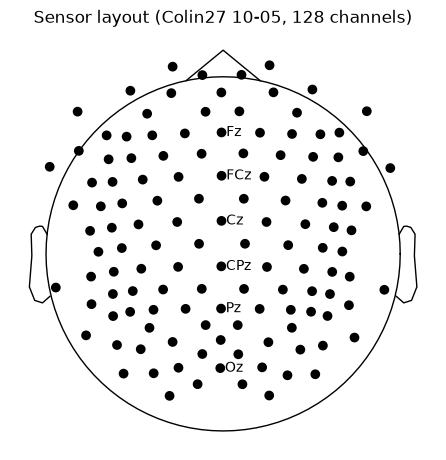

In [4]:
ref = mne.channels.make_standard_montage("colin27_1005")
ref.rename_channels({"I1": "O9", "I2": "O10"})
not_in_ref = [c for c in ep.ch_names if c not in ref.ch_names]

# So sánh trong cùng hệ tọa độ "head": gán montage chuẩn vào một info rỗng cùng tên kênh,
# vì MNE đổi vị trí sang hệ head (theo fiducial) khi set_montage.
info_ref = mne.create_info(ep.ch_names, SFREQ, "eeg")
info_ref.set_montage(ref)
pos_ref = np.array([ch["loc"][:3] for ch in info_ref["chs"]])
pos_ep = np.array([ch["loc"][:3] for ch in ep.info["chs"]])
dist_mm = np.linalg.norm(pos_ref - pos_ep, axis=1) * 1000
print(f"Kênh không có trong colin27_1005: {not_in_ref or 'không'}")
print(f"Sai lệch vị trí so với montage chuẩn: max {dist_mm.max():.3f} mm")

midline = ["Fz", "FCz", "Cz", "CPz", "Pz", "Oz"]
print("Kênh đường giữa dùng trong phân tích:", [c for c in midline if c in ep.ch_names])

fig, ax = plt.subplots(figsize=(5.5, 5.5))
ep.plot_sensors(kind="topomap", show_names=midline, axes=ax, show=False)
ax.set_title("Sensor layout (Colin27 10-05, 128 channels)")
plt.show()

## 3. Kiểm kê 42 đối tượng

Đọc header + metadata của từng file (không nạp dữ liệu, chạy nhanh). Kiểm tra cùng thứ tự kênh ở cả 42 người, và đếm epoch theo điều kiện, tách riêng trial trả lời đúng.

In [5]:
ref_names = ep.ch_names
inv_id = {v: k for k, v in EVENT_ID.items()}
rows = []
for sub in SUBJECTS:
    e = mne.read_epochs(epoch_path(sub), preload=False)
    meta = e.metadata
    cond = pd.Series(e.events[:, 2]).map(inv_id).values
    correct = meta["correct"].values.astype(bool)
    row = {"subject": sub, "sfreq": e.info["sfreq"], "n_channels": len(e.ch_names),
           "n_times": len(e.times), "same_ch_order": e.ch_names == ref_names}
    for c in EVENT_ID:
        row[f"n_{c}"] = int((cond == c).sum())
        row[f"n_{c}_correct"] = int(((cond == c) & correct).sum())
    row["target_rt_ms"] = meta.loc[(cond == "target") & correct, "rt_ms"].mean()
    rows.append(row)
subjects_df = pd.DataFrame(rows).set_index("subject")

subjects_df["group"] = np.where(subjects_df.index.isin(TASK_MISUNDERSTOOD), "task-misunderstood", "normal")
subjects_df["high_impedance"] = subjects_df.index.isin(HIGH_IMPEDANCE)
subjects_df["paper_irregular"] = subjects_df.index.isin(PAPER_LISTED_IRREGULAR)

print("Tần số lấy mẫu:", subjects_df.sfreq.unique(), "| số kênh:", subjects_df.n_channels.unique(),
      "| số mẫu:", subjects_df.n_times.unique())
print("Cùng thứ tự kênh ở cả 42 người:", bool(subjects_df.same_ch_order.all()))
subjects_df

Tần số lấy mẫu: [250.] | số kênh: [128] | số mẫu: [301]
Cùng thứ tự kênh ở cả 42 người: True


,sfreq,n_channels,n_times,same_ch_order,n_standard,n_standard_correct,n_target,n_target_correct,n_distractor,n_distractor_correct,target_rt_ms,group,high_impedance,paper_irregular
subject,,,,,,,,,,,,,,
sub-01,250.0,128,301,True,494,479,80,61,80,51,572.967213,normal,False,False
sub-02,250.0,128,301,True,491,475,79,79,80,1,384.582278,task-misunderstood,False,False
sub-03,250.0,128,301,True,476,475,81,81,80,70,507.716049,normal,False,False
sub-04,250.0,128,301,True,498,498,81,79,81,76,552.911392,normal,False,False
sub-05,250.0,128,301,True,489,489,79,79,76,68,428.772152,normal,False,False
sub-06,250.0,128,301,True,483,482,78,75,78,75,575.800000,normal,False,False
sub-07,250.0,128,301,True,241,238,48,37,44,34,675.027027,normal,False,False
sub-08,250.0,128,301,True,494,492,81,69,79,67,561.260870,normal,False,False
sub-09,250.0,128,301,True,495,495,78,68,81,74,593.411765,normal,False,False


### Cờ chất lượng từ pipeline tiền xử lý (`qc_summary.csv`)

In [6]:
qc = pd.read_csv(QC_SUMMARY).set_index("subject")
qc_cols = ["task_misunderstood", "irregular_recording", "high_impedance", "n_bad_channels",
           "n_ic_excluded", "pct_trials_dropped", "fp1_p99_after_ica_uv"]
print(qc[["n_bad_channels", "n_ic_excluded", "pct_trials_dropped"]].describe().round(2))
flagged = qc[qc.task_misunderstood | qc.irregular_recording | qc.high_impedance | (qc.pct_trials_dropped > 10)]
flagged[qc_cols]

       n_bad_channels  n_ic_excluded  pct_trials_dropped
count           42.00          42.00               42.00
mean             2.90          14.95                2.99
std              3.41           4.71                7.77
min              0.00           6.00                0.00
25%              0.00          12.25                0.50
50%              2.00          15.00                0.90
75%              4.00          17.75                2.33
max             14.00          25.00               49.50


,task_misunderstood,irregular_recording,high_impedance,n_bad_channels,n_ic_excluded,pct_trials_dropped,fp1_p99_after_ica_uv
subject,,,,,,,
sub-02,True,False,False,0,16,1.5,28.3
sub-07,False,False,False,2,6,49.5,53.6
sub-13,False,True,False,1,6,0.9,21.3
sub-14,True,False,False,5,10,12.6,66.0
sub-15,False,True,False,3,13,0.6,20.2
sub-17,True,False,False,5,21,5.5,25.5
sub-23,False,True,True,14,14,1.0,48.2
sub-24,False,True,True,6,7,1.2,28.0
sub-32,False,False,True,7,18,0.3,18.3


## 4. Phân bố kích thích Standard / Target / Distractor

Thiết kế oddball thị giác: khoảng 75% standard, 12% target, 12% distractor (660 kích thích/người). Bài toán phân loại chính là **standard vs target**, chỉ lấy trial trả lời đúng, loại 3 người hiểu sai nhiệm vụ (sub-02, sub-14, sub-17).

Toàn bộ 42 người (epoch giữ lại sau QC):
                n   pct
standard    20375  75.4
target       3326  12.3
distractor   3333  12.3

Tập phân loại (39 người, trả lời đúng): 21878 trial = 18927 standard + 2951 target (13.5% target)


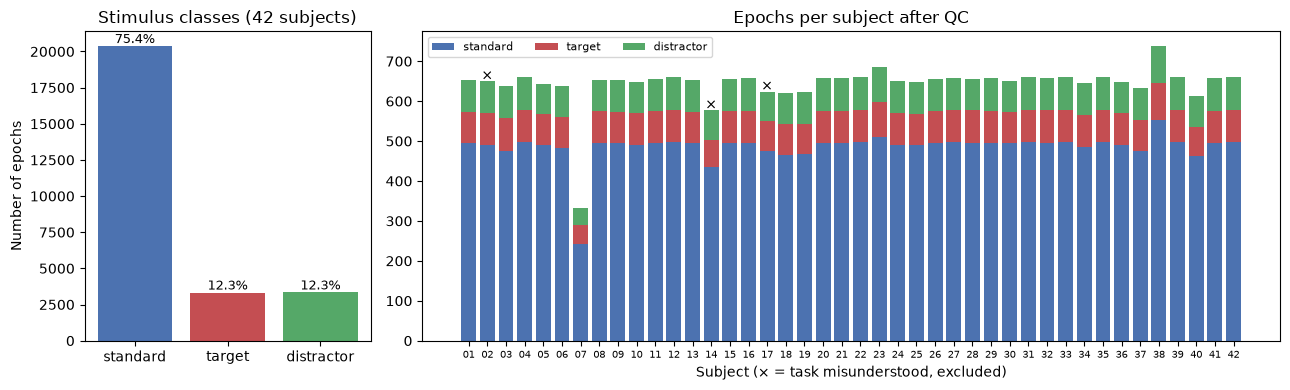

In [7]:
conds = list(EVENT_ID)
all_counts = subjects_df[[f"n_{c}" for c in conds]].sum()
all_counts.index = conds
print("Toàn bộ 42 người (epoch giữ lại sau QC):")
print(pd.DataFrame({"n": all_counts, "pct": (all_counts / all_counts.sum() * 100).round(1)}))

clf = subjects_df[subjects_df.group == "normal"]
n_std, n_tgt = clf["n_standard_correct"].sum(), clf["n_target_correct"].sum()
print(f"\nTập phân loại ({len(clf)} người, trả lời đúng): {n_std + n_tgt} trial = "
      f"{n_std} standard + {n_tgt} target ({n_tgt / (n_std + n_tgt):.1%} target)")

fig, axes = plt.subplots(1, 2, figsize=(13, 4), gridspec_kw={"width_ratios": [1, 3]})
colors = {"standard": "#4c72b0", "target": "#c44e52", "distractor": "#55a868"}
axes[0].bar(conds, all_counts.values, color=[colors[c] for c in conds])
for i, v in enumerate(all_counts.values):
    axes[0].text(i, v, f"{v / all_counts.sum():.1%}", ha="center", va="bottom", fontsize=9)
axes[0].set_ylabel("Number of epochs")
axes[0].set_title("Stimulus classes (42 subjects)")

bottom = np.zeros(len(subjects_df))
for c in conds:
    axes[1].bar(subjects_df.index.str[4:], subjects_df[f"n_{c}"], bottom=bottom, color=colors[c], label=c)
    bottom += subjects_df[f"n_{c}"].values
for i, s in enumerate(subjects_df.index):
    if s in TASK_MISUNDERSTOOD:
        axes[1].text(i, bottom[i] + 5, "×", ha="center", color="k", fontsize=10)
axes[1].set_xlabel("Subject (× = task misunderstood, excluded)")
axes[1].set_title("Epochs per subject after QC")
axes[1].legend(ncol=3, fontsize=8)
axes[1].tick_params(axis="x", labelsize=7)
fig.tight_layout()
plt.show()

## 5. Hành vi: thời gian phản ứng với target

Đối chiếu với Bảng 5 của paper dataset (39 người): RT target 542,1 ± 65,5 ms. Ô dưới tính trên các epoch target trả lời đúng còn lại sau QC, nên có thể lệch nhẹ so với con số tính trên toàn bộ marker.

RT target (39 người, trung bình theo người, epoch sau QC): 542.0 ± 65.1 ms (min 418, max 675)
RT target theo qc_summary (toàn bộ marker): 542.1 ± 65.5 ms
Tỉ lệ bấm nhầm distractor: nhóm chuẩn 9.6% vs nhóm hiểu sai 90.9%


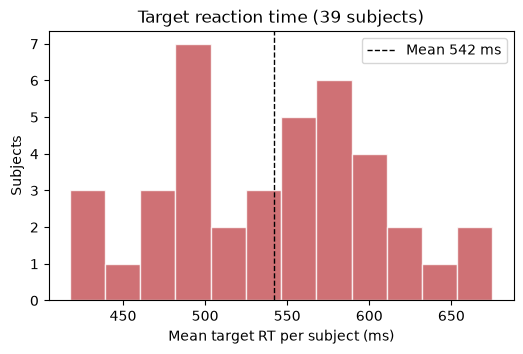

In [8]:
rt = clf["target_rt_ms"]
print(f"RT target (39 người, trung bình theo người, epoch sau QC): {rt.mean():.1f} ± {rt.std():.1f} ms "
      f"(min {rt.min():.0f}, max {rt.max():.0f})")
print(f"RT target theo qc_summary (toàn bộ marker): {qc.loc[clf.index, 'target_rt_ms'].mean():.1f} ± "
      f"{qc.loc[clf.index, 'target_rt_ms'].std():.1f} ms")
print(f"Tỉ lệ bấm nhầm distractor: nhóm chuẩn {qc.loc[clf.index, 'false_alarm_distractor_pct'].mean():.1f}% "
      f"vs nhóm hiểu sai {qc.loc[sorted(TASK_MISUNDERSTOOD), 'false_alarm_distractor_pct'].mean():.1f}%")

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.hist(rt, bins=12, color="#c44e52", alpha=0.8, edgecolor="white")
ax.axvline(rt.mean(), color="k", ls="--", lw=1, label=f"Mean {rt.mean():.0f} ms")
ax.set_xlabel("Mean target RT per subject (ms)")
ax.set_ylabel("Subjects")
ax.set_title("Target reaction time (39 subjects)")
ax.legend()
plt.show()

## Tóm tắt

- 42 file epoch đồng nhất: 250 Hz, 128 kênh (cùng thứ tự, montage Colin27 10-05), 301 mẫu (−200..+1000 ms).
- Tỉ lệ kích thích sau QC xấp xỉ 75% / 12% / 12% (standard / target / distractor).
- Tập phân loại standard vs target: 39 người, chỉ trial trả lời đúng — đầu vào chung của V4 (đặc trưng), V5 (ML baseline) và V6 (EEGNet), đánh giá bằng `GroupKFold(n_splits=5)` theo người.
- Lớp target chiếm khoảng 13,5% nên cần metric chịu được mất cân bằng (balanced accuracy, ROC-AUC, PR-AUC).